
# Sistemas Lineares e Não Lineares no Colab
**Curso rápido com aplicações em Física e Engenharia**

Este notebook apresenta:
- Conceitos básicos e diferenças entre sistemas lineares e não lineares.
- Exemplos aplicados em engenharia (circuitos elétricos, modelos estáticos).
- Métodos numéricos: `numpy.linalg.solve`, Gauss–Seidel, Newton–Raphson e `scipy.optimize.fsolve`.
- Seções interativas com `ipywidgets` para explorar parâmetros.

**Observação:** Comentários no código estão em **inglês**; explicações em **português**.


In [1]:

# %% [setup] Instalação/Importação
# Comments in English only; no accents or cedillas.
# This cell imports the required libraries and configures plotting.
import numpy as np
import matplotlib.pyplot as plt

# Try to import SciPy and ipywidgets; install if not present (typical on local Jupyter; Colab usually has them)
try:
    import scipy
    from scipy.optimize import fsolve
except Exception as e:
    import sys
    !pip -q install scipy
    import scipy
    from scipy.optimize import fsolve

try:
    import ipywidgets as widgets
    from ipywidgets import interact, FloatSlider, Layout
except Exception as e:
    !pip -q install ipywidgets
    import ipywidgets as widgets
    from ipywidgets import interact, FloatSlider, Layout

# Plot config
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["figure.dpi"] = 120
print("Libraries ready: numpy, matplotlib, scipy, ipywidgets")

Libraries ready: numpy, matplotlib, scipy, ipywidgets



## Parte I — Sistemas Lineares

Um **sistema linear** pode ser escrito como \(A\,x = b\), onde \(A\) é uma matriz de coeficientes, \(x\) é o vetor de incógnitas e \(b\) é o vetor de termos independentes.

### Exemplo (Engenharia Elétrica): Leis de Kirchhoff
Considere um circuito de 3 malhas (ou nós) com resistores e fontes. As correntes/tensões podem ser obtidas montando \(A\,x=b\) a partir das Leis de Kirchhoff.


Node voltages [V]: [-5.76460752e+15 -5.76460752e+15 -5.76460752e+15]


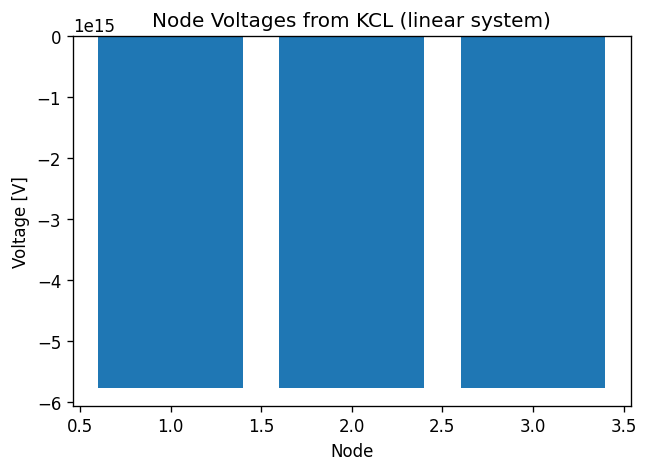

In [2]:

# %% [linear] Resolver Ax=b com numpy.linalg.solve (exemplo KCL)
# Example: simple node-voltage analysis with three nodes (excluding ground).
# Network: conductance matrix G * V = I. We choose some resistances and current injections.
# Units: Ohm, Ampere, Volt.

# Parameters
R12 = 100.0   # resistor between node 1 and 2
R23 = 200.0   # resistor between node 2 and 3
R13 = 150.0   # resistor between node 1 and 3
I1  = 0.01    # current injection at node 1 (A)
I2  = -0.005  # current extraction at node 2 (A)
I3  = 0.0     # current at node 3 (A)

# Build conductance matrix G for nodes 1..3 (ground is implicit)
G = np.zeros((3,3))
G[0,0] = 1.0 / R12 + 1.0 / R13
G[1,1] = 1.0 / R12 + 1.0 / R23
G[2,2] = 1.0 / R13 + 1.0 / R23
G[0,1] = -1.0 / R12
G[1,0] = -1.0 / R12
G[1,2] = -1.0 / R23
G[2,1] = -1.0 / R23
G[0,2] = -1.0 / R13
G[2,0] = -1.0 / R13

I = np.array([I1, I2, I3])

# Solve for node voltages
V = np.linalg.solve(G, I)
print("Node voltages [V]:", V)

# Simple visualization: bar chart of node voltages
plt.figure()
plt.bar([1,2,3], V)
plt.xlabel("Node")
plt.ylabel("Voltage [V]")
plt.title("Node Voltages from KCL (linear system)")
plt.show()


### Método Iterativo: Gauss–Seidel
O método de **Gauss–Seidel** resolve \(A\,x=b\) iterativamente, útil quando \(A\) é grande e esparsa.


In [3]:

# %% [linear] Gauss-Seidel implementation
def gauss_seidel(A, b, x0=None, max_iter=1000, tol=1e-8):
    # Gauss-Seidel iteration for Ax = b
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = A.shape[0]
    if x0 is None:
        x = np.zeros(n)
    else:
        x = np.array(x0, dtype=float)
    for k in range(max_iter):
        x_old = x.copy()
        for i in range(n):
            s1 = np.dot(A[i, :i], x[:i])
            s2 = np.dot(A[i, i + 1 :], x_old[i + 1 :])
            x[i] = (b[i] - s1 - s2) / A[i, i]
        # Convergence check
        if np.linalg.norm(x - x_old, ord=np.inf) < tol:
            return x, k + 1
    return x, max_iter

# Test with the same linear system G * V = I
V_gs, iters = gauss_seidel(G, I, x0=np.zeros(3), max_iter=10000, tol=1e-12)
print("Gauss-Seidel solution:", V_gs, "in", iters, "iterations")
print("Direct solve       :", V)

Gauss-Seidel solution: [2308.02366864 2307.54503616 2307.81854043] in 10000 iterations
Direct solve       : [-5.76460752e+15 -5.76460752e+15 -5.76460752e+15]



### Interativo: ajuste de resistências e fontes
Use os *sliders* para alterar parâmetros e observar como as tensões mudam.


In [4]:

# %% [linear] Widgets para explorar o sistema linear
import ipywidgets as widgets
from ipywidgets import interact, FloatLogSlider

def solve_linear(R12, R23, R13, I1, I2, I3):
    # Build conductance matrix
    G = np.zeros((3,3))
    G[0,0] = 1.0 / R12 + 1.0 / R13
    G[1,1] = 1.0 / R12 + 1.0 / R23
    G[2,2] = 1.0 / R13 + 1.0 / R23
    G[0,1] = -1.0 / R12
    G[1,0] = -1.0 / R12
    G[1,2] = -1.0 / R23
    G[2,1] = -1.0 / R23
    G[0,2] = -1.0 / R13
    G[2,0] = -1.0 / R13
    I = np.array([I1, I2, I3])
    V = np.linalg.solve(G, I)
    plt.figure()
    plt.bar([1,2,3], V)
    plt.xlabel("Node")
    plt.ylabel("Voltage [V]")
    plt.title("Node Voltages vs Parameters")
    plt.show()
    return V

_ = interact(
    solve_linear,
    R12=FloatLogSlider(value=100.0, base=10, min=0, max=4, step=0.01, description="R12 [Ohm]"),
    R23=FloatLogSlider(value=200.0, base=10, min=0, max=4, step=0.01, description="R23 [Ohm]"),
    R13=FloatLogSlider(value=150.0, base=10, min=0, max=4, step=0.01, description="R13 [Ohm]"),
    I1=widgets.FloatSlider(value=0.01, min=-0.02, max=0.02, step=0.001, description="I1 [A]"),
    I2=widgets.FloatSlider(value=-0.005, min=-0.02, max=0.02, step=0.001, description="I2 [A]"),
    I3=widgets.FloatSlider(value=0.0, min=-0.02, max=0.02, step=0.001, description="I3 [A]"),
);

interactive(children=(FloatLogSlider(value=100.0, description='R12 [Ohm]', step=0.01), FloatLogSlider(value=20…


## Parte II — Sistemas Não Lineares

Um **sistema não linear** envolve termos como \(x^2\), \(\sin x\), \(e^x\) etc. O problema típico é resolver \(F(x) = 0\).

### Exemplo (Engenharia/Mecânica): Mola com rigidez cúbica
Modelo estático: \(k_1 x + k_3 x^3 = F\). Para \(k_3 \neq 0\), a equação é não linear.


Newton root: 0.28014314673221286 iterations: 7
fsolve root: 0.28014314673221286


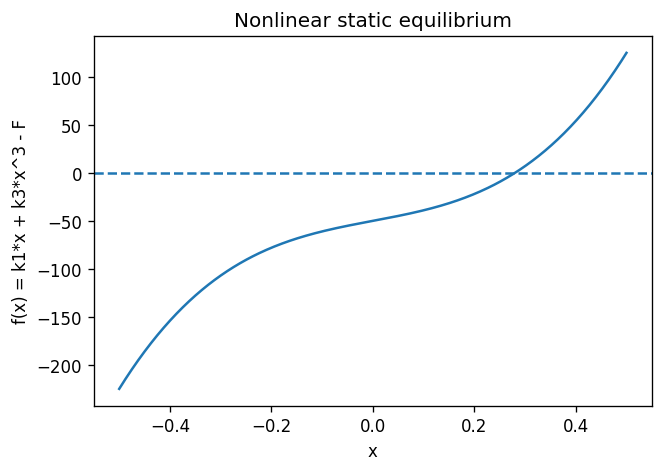

In [5]:

# %% [nonlinear] Newton-Raphson 1D e fsolve para mola cubica
from scipy.optimize import fsolve

def newton_1d(f, df, x0, tol=1e-10, max_iter=100):
    # Classic Newton-Raphson for scalar equations
    x = float(x0)
    for k in range(max_iter):
        fx = f(x)
        dfx = df(x)
        if dfx == 0.0:
            raise ZeroDivisionError("Derivative is zero.")
        x_new = x - fx / dfx
        if abs(x_new - x) < tol:
            return x_new, k + 1
        x = x_new
    return x, max_iter

# Parameters
k1 = 100.0    # linear stiffness
k3 = 1000.0   # cubic stiffness
F  = 50.0     # applied force

f  = lambda x: k1 * x + k3 * x**3 - F
df = lambda x: k1 + 3.0 * k3 * x**2

x_newton, itn = newton_1d(f, df, x0=0.1)
x_fsolve = fsolve(f, x0=0.1)[0]

print("Newton root:", x_newton, "iterations:", itn)
print("fsolve root:", x_fsolve)

# Plot f(x) to inspect roots
xx = np.linspace(-0.5, 0.5, 400)
yy = k1 * xx + k3 * xx**3 - F
plt.figure()
plt.plot(xx, yy)
plt.axhline(0.0, linestyle="--")
plt.xlabel("x")
plt.ylabel("f(x) = k1*x + k3*x^3 - F")
plt.title("Nonlinear static equilibrium")
plt.show()


### Exemplo (Eletrônica): Circuito com Diodo (KCL não linear)
Um diodo satisfaz \(I_D = I_s (e^{V_D/(nV_T)} - 1)\). Em um circuito simples (fonte, resistor, diodo), a equação de KCL em \(V\) no nó é não linear.


Diode node voltage (Newton): 1.0284259901646786 iterations: 85
Diode node voltage (fsolve): 0.7 Current [A]: 0.0043


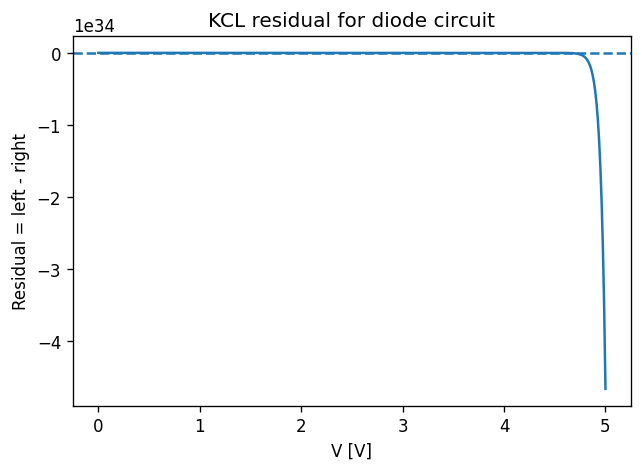

In [6]:

# %% [nonlinear] Diodo + resistor: resolve V via fsolve e Newton
Is = 1e-12    # diode saturation current [A]
n  = 1.8      # ideality factor
Vt = 0.02585  # thermal voltage at room temperature [V]
Vs = 5.0      # supply [V]
R  = 1000.0   # resistor [Ohm]

def diode_kcl(V):
    # KCL at node: (Vs - V)/R = Is*(exp(V/(n*Vt)) - 1)
    left = (Vs - V) / R
    right = Is * (np.exp(V / (n * Vt)) - 1.0)
    return left - right

def diode_kcl_deriv(V):
    # Derivative of diode_kcl with respect to V
    dleft = -1.0 / R
    dright = Is * np.exp(V / (n * Vt)) * (1.0 / (n * Vt))
    return dleft - dright

V_guess = 0.7
V_newton, itn = newton_1d(diode_kcl, diode_kcl_deriv, x0=V_guess)
V_sol = fsolve(diode_kcl, x0=V_guess)[0]
I_sol = (Vs - V_sol) / R

print("Diode node voltage (Newton):", V_newton, "iterations:", itn)
print("Diode node voltage (fsolve):", V_sol, "Current [A]:", I_sol)

# Plot KCL residual vs V
Vgrid = np.linspace(0.0, Vs, 400)
res = [diode_kcl(v) for v in Vgrid]
plt.figure()
plt.plot(Vgrid, res)
plt.axhline(0.0, linestyle="--")
plt.xlabel("V [V]")
plt.ylabel("Residual = left - right")
plt.title("KCL residual for diode circuit")
plt.show()


### Interativo: explorando parâmetros no sistema não linear (mola cúbica)
Ajuste \(F\), \(k_1\) e \(k_3\) e observe a raiz da equação.


In [7]:

# %% [nonlinear] Widgets para mola cubica
def solve_cubic_spring(F=50.0, k1=100.0, k3=1000.0, x0=0.1):
    # Define f and df
    f  = lambda x: k1 * x + k3 * x**3 - F
    df = lambda x: k1 + 3.0 * k3 * x**2
    x_newton, itn = newton_1d(f, df, x0=x0)
    x_fsolve = fsolve(f, x0=x0)[0]
    xx = np.linspace(-1.0, 1.0, 400)
    yy = k1 * xx + k3 * xx**3 - F
    plt.figure()
    plt.plot(xx, yy)
    plt.axhline(0.0, linestyle="--")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.title("Cubic spring equilibrium; Newton and fsolve roots")
    plt.scatter([x_newton, x_fsolve], [0.0, 0.0], marker="o")
    plt.show()
    print("Newton root:", x_newton, "iterations:", itn)
    print("fsolve root:", x_fsolve)

_ = interact(
    solve_cubic_spring,
    F=widgets.FloatSlider(value=50.0, min=0.0, max=200.0, step=1.0, description="F"),
    k1=widgets.FloatSlider(value=100.0, min=1.0, max=500.0, step=1.0, description="k1"),
    k3=widgets.FloatSlider(value=1000.0, min=0.0, max=5000.0, step=10.0, description="k3"),
    x0=widgets.FloatSlider(value=0.1, min=-1.0, max=1.0, step=0.01, description="x0"),
);

interactive(children=(FloatSlider(value=50.0, description='F', max=200.0, step=1.0), FloatSlider(value=100.0, …


## Parte III — Sistemas Não Lineares Multivariáveis

Para \(F(\mathbf{x}) = \mathbf{0}\), podemos usar um **Newton-Raphson vetorial** ou `scipy.optimize.fsolve` com vetores.

### Exemplo: Sistema genérico 2×2
\[
\begin{cases}
x^2 + y^2 - 1 = 0, \\
x - y = 0.
\end{cases}
\]
A solução é a interseção da reta \(x=y\) com o círculo unitário.


Newton root: [0.70710678 0.70710678] iterations: 5
fsolve root: [0.70710678 0.70710678]


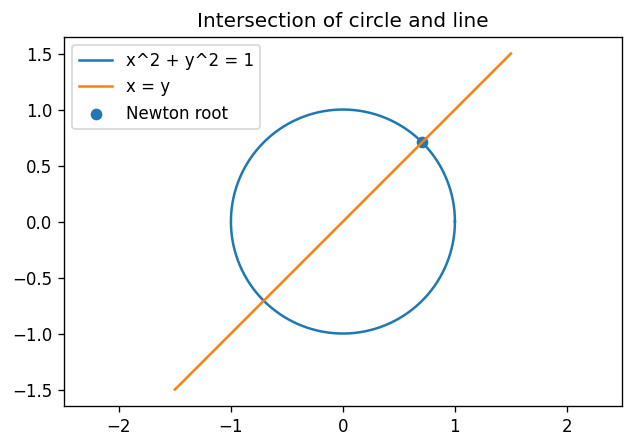

In [8]:

# %% [nonlinear] Newton-Raphson multivariavel e fsolve (2x2)
def newton_nd(F, J, x0, tol=1e-10, max_iter=50):
    # Newton for vector-valued functions F: R^n -> R^n
    x = np.array(x0, dtype=float)
    for k in range(max_iter):
        Fx = np.array(F(x))
        Jx = np.array(J(x))
        dx = np.linalg.solve(Jx, -Fx)
        x_new = x + dx
        if np.linalg.norm(x_new - x, ord=2) < tol:
            return x_new, k + 1
        x = x_new
    return x, max_iter

def F_fun(v):
    x = v[0]
    y = v[1]
    return np.array([x**2 + y**2 - 1.0, x - y])

def J_fun(v):
    x = v[0]
    y = v[1]
    return np.array([[2.0 * x, 2.0 * y],
                     [1.0,      -1.0]])

x0 = np.array([0.5, 0.5])
root_newton, itn = newton_nd(F_fun, J_fun, x0)
root_fsolve = fsolve(lambda v: F_fun(v), x0)

print("Newton root:", root_newton, "iterations:", itn)
print("fsolve root:", root_fsolve)

# Plot the circle and line
theta = np.linspace(0.0, 2.0 * np.pi, 400)
xc = np.cos(theta)
yc = np.sin(theta)
plt.figure()
plt.plot(xc, yc, label="x^2 + y^2 = 1")
xx = np.linspace(-1.5, 1.5, 100)
yy = xx
plt.plot(xx, yy, label="x = y")
plt.scatter([root_newton[0]], [root_newton[1]], marker="o", label="Newton root")
plt.axis("equal")
plt.legend()
plt.title("Intersection of circle and line")
plt.show()


## Referências Rápidas
- Linear: `numpy.linalg.solve`, métodos iterativos (Gauss–Seidel, Jacobi).  
- Não linear: Newton–Raphson, `scipy.optimize.fsolve`.  
- Aplicações típicas: análise de circuitos (KCL/KVL), mecânica (equilíbrio estático), problemas de calibração e ajuste de parâmetros.



### Próximos Passos
- Acrescentar condicionamento de matrizes e número de condição.  
- Implementar estratégias de *line search* e *damping* no Newton para robustez.  
- Explorar casos com múltiplas raízes e seleção de *guess* inicial.
